# Phase 2a: Baseline IDS - Logistic Regression
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Trains on the **balanced** training set (Phase 1b) and evaluates on the **untouched** validation and test sets (original class distribution).
Run `phase1_preprocessing.ipynb` and `phase1b_smote_balancing.ipynb` first.

## Step 0: Imports and settings

In [1]:
import os, json, time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
print("Setup done")

Setup done


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Train Logistic Regression
Hyperparameters follow the reference paper: L2 penalty, C = 1.0, lbfgs solver.

In [3]:
model = LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=1000, random_state=42)

t0 = time.time()
model.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s | iterations: {model.n_iter_[0]}")

joblib.dump(model, f"{MODEL_DIR}/logreg_baseline.joblib")

c:\Users\arvin\Desktop\projects\adversarial-ids\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training time: 34.6 s | iterations: 237


['models/logreg_baseline.joblib']

## Step 3: Evaluation function

In [4]:
def evaluate(model, X, y, name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y, y_pred),
        "precision":   precision_score(y, y_pred, zero_division=0),
        "recall":      recall_score(y, y_pred),
        "f1":          f1_score(y, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred, y_prob

## Step 4: Results on validation and test sets

In [5]:
val_m,  val_pred,  val_prob  = evaluate(model, X_val,  y_val,  "validation")
test_m, test_pred, test_prob = evaluate(model, X_test, y_test, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.7903       0.7908
precision            0.4459       0.4464
recall               0.9953       0.9951
f1                   0.6159       0.6163
specificity          0.7487       0.7493
fpr                  0.2513       0.2507
fnr                  0.0047       0.0049
roc_auc              0.9739       0.9745

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9987    0.7493    0.8562    314259
      Attack     0.4464    0.9951    0.6163     63861

    accuracy                         0.7908    378120
   macro avg     0.7225    0.8722    0.7363    378120
weighted avg     0.9054    0.7908    0.8157    378120



## Step 5: Confusion matrix and ROC curve (test set)

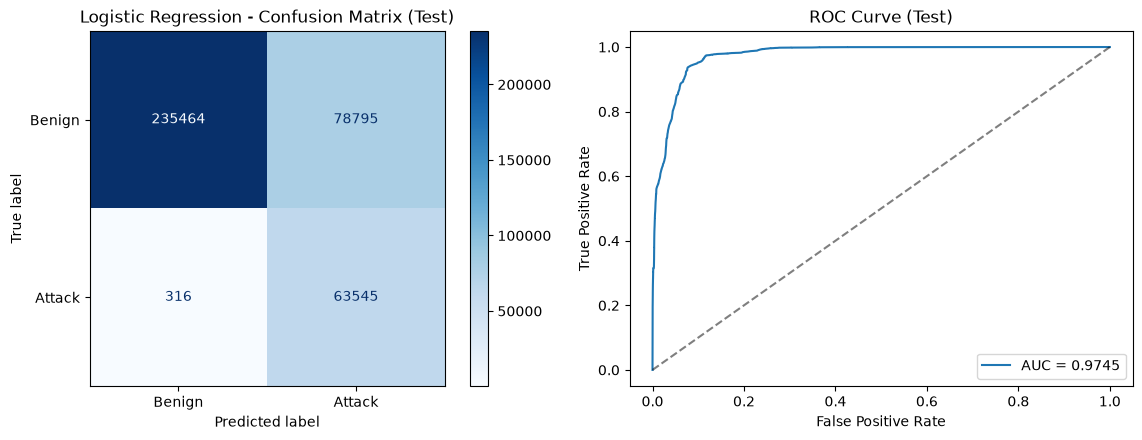

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("Logistic Regression - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/logreg_clean_cm_roc.png", dpi=150)
plt.show()

## Step 6: Save results (used later for baseline vs adversarial vs robust comparison)

In [7]:
with open(f"{RESULT_DIR}/logreg_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time}, f, indent=2)
print("Saved:", sorted(os.listdir(RESULT_DIR)))
print("Model saved to", f"{MODEL_DIR}/logreg_baseline.joblib")

Saved: ['logreg_clean_cm_roc.png', 'logreg_clean_metrics.json']
Model saved to models/logreg_baseline.joblib


## Notes for the report
- Accuracy alone is misleading on imbalanced IDS data, so report precision, recall, F1, FPR and FNR as well.
- **FNR** is the key security metric here: missed attacks are exactly what adversarial evasion will try to increase in Phase 3.
- Logistic Regression is differentiable, so FGSM/PGD can be applied to it directly using its weights (`model.coef_`, `model.intercept_`).